In [4]:
!pip install -q pandas matplotlib google-genai

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from google import genai
from getpass import getpass

# Initialize expense database
expenses = pd.DataFrame(
    columns=["Date", "Description", "Amount", "Category"]
)

# Set monthly budget
monthly_budget = 15000

# Configure Gemini AI (optional)
api_key = getpass("Enter Gemini API Key (press Enter to skip): ")

client = None

if api_key.strip():
    client = genai.Client(api_key=api_key)

print("AI Expense Management Agent Initialized Successfully!")

Enter Gemini API Key (press Enter to skip): ··········
AI Expense Management Agent Initialized Successfully!


In [6]:
def categorize_expense(description):

    description = description.lower()

    categories = {
        "Food": ["food", "restaurant", "pizza", "lunch", "dinner",
                 "breakfast", "grocery", "coffee"],
        "Travel": ["bus", "train", "flight", "taxi", "uber",
                   "petrol", "fuel", "travel"],
        "Shopping": ["clothes", "shoes", "shopping", "amazon",
                     "mobile", "electronics"],
        "Education": ["book", "course", "college", "fees",
                      "tuition", "education"],
        "Healthcare": ["doctor", "medicine", "hospital",
                       "medical", "health"],
        "Entertainment": ["movie", "game", "netflix",
                         "entertainment", "concert"],
        "Utilities": ["electricity", "water", "internet",
                      "mobile recharge", "bill"]
    }

    for category, keywords in categories.items():
        if any(word in description for word in keywords):
            return category

    return "Other"


def add_expense(description, amount, date=None):

    global expenses

    if amount <= 0:
        print("Please enter a valid positive amount.")
        return

    if date is None:
        date = datetime.now().strftime("%Y-%m-%d")

    category = categorize_expense(description)

    new_expense = pd.DataFrame([{
        "Date": date,
        "Description": description,
        "Amount": float(amount),
        "Category": category
    }])

    expenses = pd.concat(
        [expenses, new_expense],
        ignore_index=True
    )

    print("\nExpense Added Successfully!")
    print("Description:", description)
    print("Amount: ₹", amount)
    print("Category:", category)


# Example expenses
add_expense("Lunch at restaurant", 250)
add_expense("Petrol for bike", 500)
add_expense("Python programming book", 700)
add_expense("Shopping clothes", 1200)
add_expense("Movie ticket", 300)


Expense Added Successfully!
Description: Lunch at restaurant
Amount: ₹ 250
Category: Food

Expense Added Successfully!
Description: Petrol for bike
Amount: ₹ 500
Category: Travel

Expense Added Successfully!
Description: Python programming book
Amount: ₹ 700
Category: Education

Expense Added Successfully!
Description: Shopping clothes
Amount: ₹ 1200
Category: Shopping

Expense Added Successfully!
Description: Movie ticket
Amount: ₹ 300
Category: Entertainment


/tmp/ipykernel_891/1160434706.py:49: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  expenses = pd.concat(


In [7]:
def analyze_expenses():

    if expenses.empty:
        print("No expenses available.")
        return

    total = expenses["Amount"].sum()

    print("\n========== EXPENSE ANALYSIS ==========")

    print("Total Expenses: ₹", total)
    print("Monthly Budget: ₹", monthly_budget)
    print("Remaining Budget: ₹", monthly_budget - total)

    print("\nCategory-wise Expenses:")

    category_total = expenses.groupby(
        "Category"
    )["Amount"].sum()

    print(category_total)

    print("\nAll Expense Records:")
    display(expenses)


analyze_expenses()


========== EXPENSE ANALYSIS ==========
Total Expenses: ₹ 2950.0
Monthly Budget: ₹ 15000
Remaining Budget: ₹ 12050.0

Category-wise Expenses:
Category
Education         700.0
Entertainment     300.0
Food              250.0
Shopping         1200.0
Travel            500.0
Name: Amount, dtype: float64

All Expense Records:


,Date,Description,Amount,Category
0,2026-11-20,Lunch at restaurant,250.0,Food
1,2026-11-20,Petrol for bike,500.0,Travel
2,2026-11-20,Python programming book,700.0,Education
3,2026-11-20,Shopping clothes,1200.0,Shopping
4,2026-11-20,Movie ticket,300.0,Entertainment


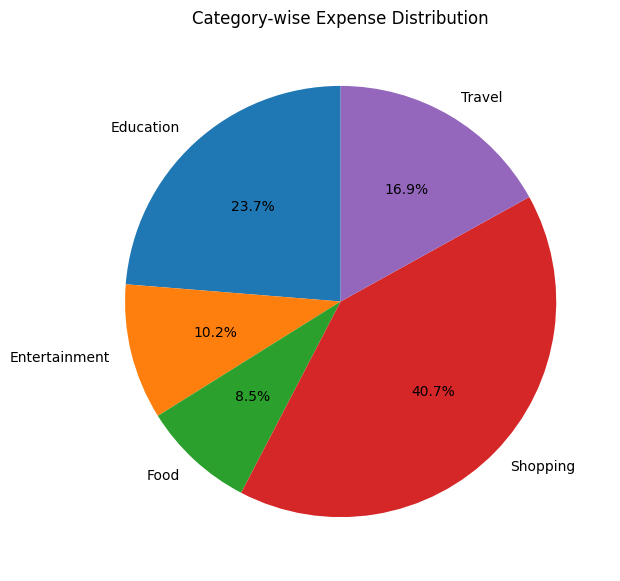

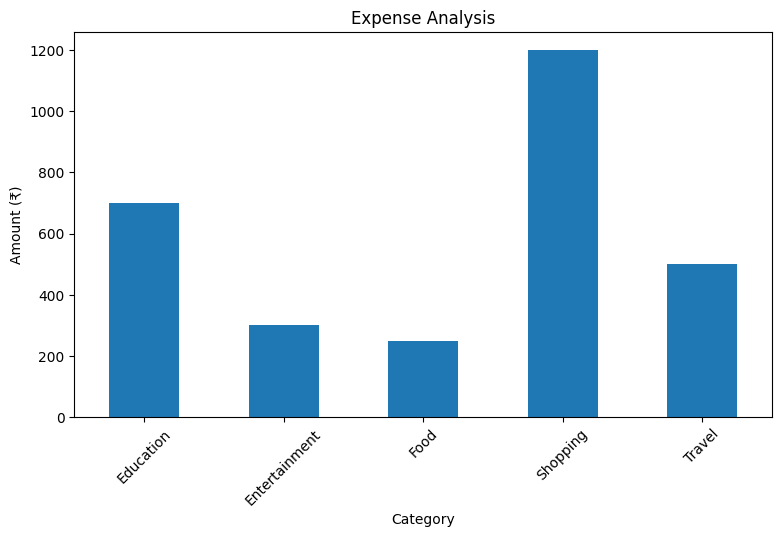

In [8]:
def visualize_expenses():

    if expenses.empty:
        print("No expenses available.")
        return

    category_total = expenses.groupby(
        "Category"
    )["Amount"].sum()

    # Pie chart
    plt.figure(figsize=(7, 7))

    plt.pie(
        category_total,
        labels=category_total.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Category-wise Expense Distribution")
    plt.show()

    # Bar chart
    plt.figure(figsize=(9, 5))

    category_total.plot(kind="bar")

    plt.title("Expense Analysis")
    plt.xlabel("Category")
    plt.ylabel("Amount (₹)")
    plt.xticks(rotation=45)
    plt.show()


visualize_expenses()

In [9]:
def budget_recommendation():

    if expenses.empty:
        print("Please add expenses first.")
        return

    total = expenses["Amount"].sum()

    category_total = expenses.groupby(
        "Category"
    )["Amount"].sum()

    highest_category = category_total.idxmax()
    highest_amount = category_total.max()

    print("\n========== SMART BUDGET ANALYSIS ==========")

    print("Total Spending: ₹", total)
    print("Highest Spending Category:", highest_category)
    print("Highest Category Amount: ₹", highest_amount)

    if total > monthly_budget:
        print("WARNING: Your spending has exceeded the budget!")
    else:
        print("You are within your budget.")

    if client:

        prompt = f"""
        You are an intelligent AI Expense Management Agent.

        Analyze the following financial information:

        Total Expenses: ₹{total}
        Monthly Budget: ₹{monthly_budget}
        Category-wise Expenses:
        {category_total.to_string()}

        Provide:
        1. Spending analysis.
        2. Highest spending category.
        3. Unnecessary expenses that could be reduced.
        4. Three practical money-saving suggestions.
        5. Budget planning for next month.

        Use simple English and practical recommendations.
        Do not invent financial transactions.
        """

        try:
            response = client.models.generate_content(
                model="gemini-2.5-flash",
                contents=prompt
            )

            print("\nAI GENERATED RECOMMENDATIONS:\n")
            print(response.text)

        except Exception as e:
            print("AI service error:", e)

    else:
        print("\nRule-based recommendations:")

        print(
            f"Review your spending on {highest_category}."
        )

        print(
            "Try reducing non-essential purchases."
        )

        print(
            "Maintain a monthly expense record."
        )


budget_recommendation()


========== SMART BUDGET ANALYSIS ==========
Total Spending: ₹ 2950.0
Highest Spending Category: Shopping
Highest Category Amount: ₹ 1200.0
You are within your budget.
AI service error: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}


In [10]:
def ai_expense_assistant(question):

    if expenses.empty:
        print("Please add some expenses first.")
        return

    total = expenses["Amount"].sum()

    category_total = expenses.groupby(
        "Category"
    )["Amount"].sum()

    highest_category = category_total.idxmax()

    remaining = monthly_budget - total

    context = f"""
    You are an AI Expense Management Agent.

    Expense Records:
    {expenses.to_string(index=False)}

    Total Expenses: ₹{total}
    Monthly Budget: ₹{monthly_budget}
    Remaining Budget: ₹{remaining}

    Category-wise Expenses:
    {category_total.to_string()}

    Highest Spending Category: {highest_category}
    """

    if client:

        prompt = context + f"""

        User Question: {question}

        Answer in simple English.
        Use the available expense records.
        Give accurate calculations and useful suggestions.
        Do not invent transactions.
        """

        try:
            response = client.models.generate_content(
                model="gemini-2.5-flash",
                contents=prompt
            )

            print("\nAI Agent:", response.text)

        except Exception as e:
            print("AI service error:", e)

    else:

        print("\nExpense Management Agent:")

        if "highest" in question.lower():
            print("Highest Spending Category:", highest_category)

        elif "total" in question.lower() or "spend" in question.lower():
            print("Total Expenses: ₹", total)

        elif "budget" in question.lower():
            print("Monthly Budget: ₹", monthly_budget)
            print("Remaining Budget: ₹", remaining)

        else:
            print("Category-wise Expenses:")
            print(category_total)


# Ask questions
ai_expense_assistant("Which category has the highest expenses?")
ai_expense_assistant("How much money did I spend?")
ai_expense_assistant("Am I within my monthly budget?")

AI service error: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}
AI service error: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}
AI service error: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (ht

In [11]:
def export_expenses():

    if expenses.empty:
        print("No expense records to export.")
        return

    filename = "AI_Expense_Report.csv"

    expenses.to_csv(filename, index=False)

    print("Expense report generated successfully!")

    from google.colab import files
    files.download(filename)


export_expenses()

Expense report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def expense_management_menu():

    global monthly_budget

    while True:

        print("\n========== AI EXPENSE MANAGEMENT AGENT ==========")
        print("1. Add New Expense")
        print("2. View All Expenses")
        print("3. Analyze Expenses")
        print("4. Visualize Expenses")
        print("5. AI Budget Recommendations")
        print("6. Ask AI Expense Assistant")
        print("7. Change Monthly Budget")
        print("8. Export Expense Report")
        print("9. Exit")

        choice = input("\nEnter your choice: ")

        if choice == "1":

            description = input("Enter expense description: ")
            amount = float(input("Enter amount: ₹"))

            add_expense(description, amount)

        elif choice == "2":

            display(expenses)

        elif choice == "3":

            analyze_expenses()

        elif choice == "4":

            visualize_expenses()

        elif choice == "5":

            budget_recommendation()

        elif choice == "6":

            question = input("Ask your question: ")
            ai_expense_assistant(question)

        elif choice == "7":

            monthly_budget = float(
                input("Enter new monthly budget: ₹")
            )

            print("Monthly budget updated successfully!")

        elif choice == "8":

            export_expenses()

        elif choice == "9":

            print("Thank you for using AI Expense Management Agent!")
            break

        else:

            print("Invalid choice. Please try again.")


expense_management_menu()


========== AI EXPENSE MANAGEMENT AGENT ==========
1. Add New Expense
2. View All Expenses
3. Analyze Expenses
4. Visualize Expenses
5. AI Budget Recommendations
6. Ask AI Expense Assistant
7. Change Monthly Budget
8. Export Expense Report
9. Exit

Enter your choice: 1
Enter expense description: Lunch at restaurant
Enter amount: ₹250

Expense Added Successfully!
Description: Lunch at restaurant
Amount: ₹ 250.0
Category: Food

========== AI EXPENSE MANAGEMENT AGENT ==========
1. Add New Expense
2. View All Expenses
3. Analyze Expenses
4. Visualize Expenses
5. AI Budget Recommendations
6. Ask AI Expense Assistant
7. Change Monthly Budget
8. Export Expense Report
9. Exit

Enter your choice: 1
Enter expense description: Petrol for bike
Enter amount: ₹250

Expense Added Successfully!
Description: Petrol for bike
Amount: ₹ 250.0
Category: Travel

========== AI EXPENSE MANAGEMENT AGENT ==========
1. Add New Expense
2. View All Expenses
3. Analyze Expenses
4. Visualize Expenses
5. AI Budget Re

,Date,Description,Amount,Category
0,2026-11-20,Lunch at restaurant,250.0,Food
1,2026-11-20,Petrol for bike,500.0,Travel
2,2026-11-20,Python programming book,700.0,Education
3,2026-11-20,Shopping clothes,1200.0,Shopping
4,2026-11-20,Movie ticket,300.0,Entertainment
5,2026-11-20,Lunch at restaurant,250.0,Food
6,2026-11-20,Petrol for bike,250.0,Travel



========== AI EXPENSE MANAGEMENT AGENT ==========
1. Add New Expense
2. View All Expenses
3. Analyze Expenses
4. Visualize Expenses
5. AI Budget Recommendations
6. Ask AI Expense Assistant
7. Change Monthly Budget
8. Export Expense Report
9. Exit


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=expenses)